In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, make_scorer, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

In [2]:
# Project paths and settings
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
from src.transformers import DropColumns, IQRClipper, ScreenTimeConsistency

DATA_PATH = PROJECT_ROOT / "data/raw/student_mental_health.csv"
MODEL_PATH = PROJECT_ROOT / "models/mental_health_risk_pipeline.joblib"

RANDOM_STATE = 42
CLASS_NAMES = ["Low", "Medium", "High"]
sns.set_theme(style="whitegrid")

Data split

In [3]:
df = pd.read_csv(DATA_PATH)

X = df.drop(columns="Mental_Health_Risk")
y = df["Mental_Health_Risk"].map({"Low": 0, "Medium": 1, "High": 2})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1600, 16)
Testing set: (400, 16)


preprocessing pipeline

In [4]:
numeric_cols = [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate",
]

ordinal_cols = [
    "Physical_Activity",
    "Diet_Quality",
    "Part_Time_Job",
    "Previous_Mental_Health_History",
]

nominal_cols = ["Gender"]

clip_cols = [
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Attendance_Rate",
]

In [5]:
def create_preprocessor():
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    ordinal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"],
            ["No", "Yes"],
            ["No", "Yes"],
        ])),
    ])

    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("numerical", numerical_pipeline, numeric_cols),
        ("ordinal", ordinal_pipeline, ordinal_cols),
        ("nominal", nominal_pipeline, nominal_cols),
    ])


def create_pipeline(model):
    return Pipeline([
        ("drop_identifier", DropColumns(["Student_ID"])),
        ("screen_time_check", ScreenTimeConsistency()),
        ("outlier_clipper", IQRClipper(clip_cols)),
        ("preprocessor", create_preprocessor()),
        ("model", model),
    ])

Cross validation and tuning

In [6]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score, average="macro", zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
    "roc_auc_ovr": "roc_auc_ovr",
}

In [7]:
# Tune Logistic Regression
logistic_search = GridSearchCV(
    estimator=create_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ),
    param_grid={
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

print(f"Best CV F1-score: {logistic_search.best_score_:.3f}")
print("Best parameters:", logistic_search.best_params_)

Best CV F1-score: 0.757
Best parameters: {'model__C': 10, 'model__class_weight': 'balanced'}


In [8]:
# Tune Random Forest
forest_search = RandomizedSearchCV(
    estimator=create_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)
    ),
    param_distributions={
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [None, 8, 16, 24],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", None],
        "model__class_weight": [None, "balanced"],
    },
    n_iter=15,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print(f"Best CV F1-score: {forest_search.best_score_:.3f}")
print("Best parameters:", forest_search.best_params_)

Best CV F1-score: 0.696
Best parameters: {'model__n_estimators': 600, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 24, 'model__class_weight': None}


Cross-validation comparison

In [9]:
searches = {
    "Logistic Regression": logistic_search,
    "Random Forest": forest_search,
}

cv_results = []

for name, search in searches.items():
    index = search.best_index_

    cv_results.append({
        "Model": name,
        "Accuracy": search.cv_results_["mean_test_accuracy"][index],
        "Precision (macro)": search.cv_results_["mean_test_precision_macro"][index],
        "Recall (macro)": search.cv_results_["mean_test_recall_macro"][index],
        "F1-score (macro)": search.cv_results_["mean_test_f1_macro"][index],
        "ROC-AUC (OvR macro)": search.cv_results_["mean_test_roc_auc_ovr"][index],
    })

comparison = pd.DataFrame(cv_results).sort_values(
    "F1-score (macro)", ascending=False
)

display(comparison.round(3))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),ROC-AUC (OvR macro)
0,Logistic Regression,0.758,0.758,0.758,0.757,0.907
1,Random Forest,0.701,0.697,0.700,0.696,0.859


Final test evaluation

In [10]:
best_name = comparison.iloc[0]["Model"]
best_pipeline = searches[best_name].best_estimator_

y_pred = best_pipeline.predict(X_test)
y_probability = best_pipeline.predict_proba(X_test)

test_results = pd.DataFrame([{
    "Model": best_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Recall (macro)": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "F1-score (macro)": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "ROC-AUC (OvR macro)": roc_auc_score(
        y_test, y_probability, multi_class="ovr", average="macro"
    ),
}])

display(test_results.round(3))

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    zero_division=0
))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),ROC-AUC (OvR macro)
0,Logistic Regression,0.772,0.774,0.772,0.773,0.918


              precision    recall  f1-score   support

         Low       0.83      0.80      0.81       132
      Medium       0.65      0.68      0.67       132
        High       0.84      0.84      0.84       136

    accuracy                           0.77       400
   macro avg       0.77      0.77      0.77       400
weighted avg       0.78      0.77      0.77       400



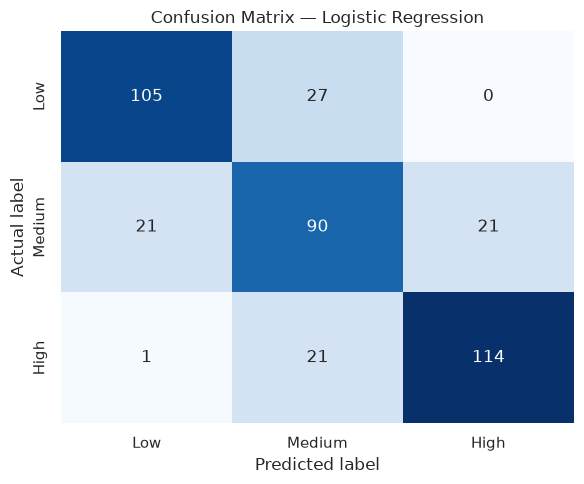

In [11]:
# Confusion matrix
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

Error analysis and limits

In [12]:
label_mapping = {0: "Low", 1: "Medium", 2: "High"}

error_analysis = X_test.copy()
error_analysis["Actual_Risk"] = y_test.map(label_mapping)
error_analysis["Predicted_Risk"] = pd.Series(
    y_pred, index=X_test.index
).map(label_mapping)
error_analysis["Confidence"] = y_probability.max(axis=1)

errors = error_analysis[
    error_analysis["Actual_Risk"] != error_analysis["Predicted_Risk"]
]

print(f"Misclassified observations: {len(errors)} / {len(X_test)}")
display(pd.crosstab(errors["Actual_Risk"], errors["Predicted_Risk"]))
display(errors.sort_values("Confidence").head(10))

Misclassified observations: 91 / 400


Predicted_Risk,High,Low,Medium
Actual_Risk,,,
High,0,1,21
Low,0,0,27
Medium,21,21,0


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual_Risk,Predicted_Risk,Confidence
1144,STU1145,21,Female,3,7.9,18.1,3.16,7.5,11.8,Low,8.3,9.5,94.3,Yes,Poor,No,Low,Medium,0.474898
502,STU0503,18,Male,1,6.7,20.5,2.57,5.1,9.3,Moderate,7.6,8.1,72.9,No,Good,No,Medium,Low,0.490324
580,STU0581,22,Non-binary,2,6.1,18.8,2.77,4.9,7.3,High,6.7,3.0,93.4,Yes,Poor,No,High,Medium,0.491342
1170,STU1171,23,Male,1,8.3,15.2,2.69,6.1,10.2,High,8.0,4.0,93.4,Yes,Average,No,Low,Medium,0.494586
310,STU0311,21,Male,5,6.4,25.3,2.50,5.2,8.5,High,7.0,NaN,97.6,No,Average,No,Low,Medium,0.497743
1310,STU1311,21,Male,1,7.4,10.2,2.69,8.5,8.8,High,6.7,7.8,92.8,No,Good,Yes,Medium,Low,0.498082
564,STU0565,24,Female,3,6.0,21.7,2.60,5.5,7.5,Low,5.2,5.9,85.1,No,Poor,No,Medium,High,0.498929
1333,STU1334,24,Female,3,5.8,17.1,2.44,6.4,8.8,Moderate,2.5,8.2,83.8,Yes,Average,No,Low,Medium,0.510776
1225,STU1226,21,Female,3,6.7,26.0,2.78,5.0,8.1,Moderate,NaN,7.2,80.2,Yes,Average,No,Low,Medium,0.511289
1017,STU1018,20,Female,1,6.5,19.5,2.48,5.7,7.2,Low,NaN,8.2,98.7,No,Good,No,Low,Medium,0.512384


Save the complete pipeline

In [13]:
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_pipeline, MODEL_PATH)

print(f"Complete pipeline saved to: {MODEL_PATH}")

Complete pipeline saved to: /home/elgmouri/projects/student-mental-health-risk-prediction/models/mental_health_risk_pipeline.joblib


La régression logistique optimisée a été sélectionnée car elle a obtenu le meilleur F1-score macro lors de la validation croisée.

Sur le jeu de test indépendant, elle obtient une accuracy de 0.772, un F1-score macro de 0.773 et un ROC-AUC macro de 0.918. Le recall de la classe High est de 0.838, ce qui est important pour identifier les étudiants à risque élevé.

Le modèle peut aider au dépistage, mais il ne remplace pas un diagnostic médical. Les données sont simulées et une validation sur des données réelles reste nécessaire.